## 1. Import library dan pengaturan

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_RAW = ROOT / "dataset_raw"
PRAPROSES = ROOT / "data" / "praproses"
MASK = ROOT / "data" / "mask"
SEGMENTASI = ROOT / "data" / "segmentasi"      # citra objek berwarna, latar hitam
HASIL = ROOT / "hasil" / "segmentasi"

KELAS = ["logam", "paper", "plastic"]
JUMLAH_CONTOH = 2      # contoh per kelas yang ditampilkan di notebook
SIMPAN_SEMUA = True    # simpan gambar perbandingan untuk semua foto

# Pengaturan GrabCut per kelas
#   iterasi : jumlah iterasi GrabCut
#   tutup   : ukuran closing morfologi pada tebakan awal (menyambung tepi yang putus)
#   tepi    : bobot petunjuk tepi (Canny). Plastik transparan dan paper putih warnanya mirip latar, jadi lebih mengandalkan tepi
#   inti    : lebar area tengah (fraksi gambar) yang dipastikan objek
PARAM = {
    "logam":   dict(iterasi=5, tutup=15, tepi=0.5, inti=0.20),   # abu-abu + pantulan: warna kurang bisa dipercaya
    "paper":   dict(iterasi=5, tutup=11, tepi=0.7, inti=0.25),   # putih/krem, mirip latar, tepi tipis
    "plastic": dict(iterasi=7, tutup=25, tepi=1.0, inti=0.15),   # transparan: hanya tepi dan pantulan yang terlihat
}

## 2. Fungsi segmentasi

In [2]:
def baca(path, gray=False):
    """Membaca gambar (aman untuk path Windows). Hasil None jika gagal dibaca."""
    try:
        data = np.fromfile(str(path), np.uint8)
        return cv2.imdecode(data, cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
    except Exception:
        return None


def tulis(path, img):
    """Menyimpan gambar (aman untuk path Windows)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix, img)
    buf.tofile(str(path))


def elips(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))


def tebakan_awal(foto, kelas):
    """Langkah 2: mask awal GrabCut (GC_BGD, GC_FGD, GC_PR_BGD, GC_PR_FGD) dan penanda apakah ada bukti objek."""
    p = PARAM[kelas]
    h, w = foto.shape[:2]

    # Petunjuk 1: jarak warna Lab terhadap warna latar (median strip tepi gambar)
    lab = cv2.cvtColor(foto, cv2.COLOR_BGR2LAB).astype(np.float32)
    m = max(3, int(0.05 * min(h, w)))
    tepi_gbr = np.concatenate([lab[:m].reshape(-1, 3), lab[-m:].reshape(-1, 3),
                               lab[:, :m].reshape(-1, 3), lab[:, -m:].reshape(-1, 3)])
    latar = np.median(tepi_gbr, axis=0)
    jarak = np.linalg.norm(lab - latar, axis=2)
    warna_beda = np.percentile(jarak, 99) >= 12             # ada piksel yang warnanya cukup beda dari latar?
    jarak = cv2.GaussianBlur(cv2.normalize(jarak, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8), (5, 5), 0)
    _, dari_warna = cv2.threshold(jarak, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Petunjuk 2: kerapatan tepi (Canny) - tidak tergantung warna, membantu logam, kertas putih, dan plastik transparan
    gray = cv2.GaussianBlur(cv2.cvtColor(foto, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    canny = cv2.Canny(gray, 40, 120)
    ada_tepi = (canny > 0).mean() >= 0.005                  # ada tepi yang cukup berarti?
    rapat = cv2.blur(canny, (31, 31))                       # rata-rata kerapatan tepi di sekitar piksel
    dari_tepi = ((rapat > 255 * 0.04) * 255).astype(np.uint8)

    # Gabungkan: warna saja, atau warna + tepi menurut bobot kelas
    kandidat = dari_warna.copy()
    if p["tepi"] > 0:
        kuat = ((rapat > 255 * 0.04 * (2 - p["tepi"])) * 255).astype(np.uint8)
        kandidat = cv2.bitwise_or(dari_warna, kuat)
    kandidat = cv2.morphologyEx(kandidat, cv2.MORPH_CLOSE, elips(p["tutup"]))
    kandidat = cv2.morphologyEx(kandidat, cv2.MORPH_OPEN, elips(7))

    # Susun mask awal
    mask = np.full((h, w), cv2.GC_PR_BGD, np.uint8)         # default: mungkin latar
    mask[kandidat > 0] = cv2.GC_PR_FGD                      # mungkin objek
    # Petunjuk 3: posisi. Area tengah dipastikan objek, tepi gambar dipastikan latar
    a, b = int(h * (0.5 - p["inti"] / 2)), int(h * (0.5 + p["inti"] / 2))
    c, d = int(w * (0.5 - p["inti"] / 2)), int(w * (0.5 + p["inti"] / 2))
    mask[a:b, c:d] = cv2.GC_FGD
    mask[:m, :] = cv2.GC_BGD
    mask[-m:, :] = cv2.GC_BGD
    mask[:, :m] = cv2.GC_BGD
    mask[:, -m:] = cv2.GC_BGD
    return mask, (warna_beda or ada_tepi)


def rapikan(biner):
    """Langkah 4a: buang bercak kecil dan isi lubang. Hanya bagian besar yang dipertahankan."""
    m = cv2.morphologyEx(biner, cv2.MORPH_OPEN, elips(5))
    kontur, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    hasil = np.zeros_like(m)
    if kontur:
        luas = [cv2.contourArea(k) for k in kontur]
        pakai = [k for k, l in zip(kontur, luas) if l >= 0.15 * max(luas)]
        cv2.drawContours(hasil, pakai, -1, 255, cv2.FILLED)   # isi lubang
    return hasil


def periksa(mask_foto):
    """Langkah 4b: periksa hasil. Return (berhasil, alasan)."""
    h, w = mask_foto.shape
    porsi = (mask_foto > 0).mean()
    if porsi < 0.03:
        return False, "objek terlalu kecil / tidak ditemukan"
    if porsi > 0.90:
        return False, "objek hampir seluruh gambar (latar ikut terambil)"
    m = max(3, int(0.05 * min(h, w)))
    tepi = np.concatenate([mask_foto[:m].ravel(), mask_foto[-m:].ravel(),
                           mask_foto[:, :m].ravel(), mask_foto[:, -m:].ravel()])
    if (tepi > 0).mean() > 0.5:
        return False, "mask menempel di sebagian besar tepi gambar (latar ikut terambil)"
    kontur, _ = cv2.findContours(mask_foto, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(kontur) > 3:
        return False, "mask terpecah menjadi banyak bagian"
    return True, ""


def segmentasi(img, kotak, kelas):
    """Langkah 1-4. Return mask 640x640 (0/255), status (True/False), alasan."""
    x1, y1, x2, y2 = kotak
    foto = img[y1:y2, x1:x2].copy()                         # hanya area foto, tanpa pita letterbox
    mask_gc, ada_bukti = tebakan_awal(foto, kelas)
    if not ada_bukti:                                       # gambar polos: area tengah yang dipaksa objek tidak boleh dianggap hasil
        return np.zeros(img.shape[:2], np.uint8), False, "tidak ada objek yang terlihat (warna dan tepi sama dengan latar)"
    bgd, fgd = np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64)
    try:
        cv2.grabCut(foto, mask_gc, None, bgd, fgd, PARAM[kelas]["iterasi"], cv2.GC_INIT_WITH_MASK)
    except cv2.error:
        return np.zeros(img.shape[:2], np.uint8), False, "GrabCut gagal dijalankan"
    biner = np.where((mask_gc == cv2.GC_FGD) | (mask_gc == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
    biner = rapikan(biner)
    ok, alasan = periksa(biner)
    mask = np.zeros(img.shape[:2], np.uint8)
    if ok:                                                  # gagal -> mask dikosongkan (ditangani manual di notebook 05)
        mask[y1:y2, x1:x2] = biner
    return mask, ok, alasan


def kecilkan(img, sisi=800, interpolasi=cv2.INTER_AREA):
    h, w = img.shape[:2]
    s = min(1.0, sisi / max(h, w))
    return cv2.resize(img, (round(w * s), round(h * s)), interpolation=interpolasi)


def overlay(img, mask):
    """Warna hijau transparan pada objek dan kontur merah di tepinya."""
    out = img.copy()
    sel = mask > 0
    out[sel] = (0.6 * img[sel] + 0.4 * np.array([0, 220, 0])).astype(np.uint8)
    kontur, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, kontur, -1, (0, 0, 255), max(2, round(min(img.shape[:2]) / 200)))
    return out


def gambar_segmentasi(r, asli, praproses_img, mask, berwarna, status):
    """5 panel berdampingan: asli, praproses, mask, berwarna, overlay pada citra asli."""
    x1, y1, x2, y2 = r.x1, r.y1, r.x2, r.y2
    asli_k = kecilkan(asli)
    # mask (koordinat 640x640) dikembalikan ke ukuran citra asli agar bisa ditumpuk di foto asli
    mask_asli = cv2.resize(mask[y1:y2, x1:x2], (asli_k.shape[1], asli_k.shape[0]), interpolation=cv2.INTER_NEAREST)
    fig, ax = plt.subplots(1, 5, figsize=(22, 4.6))
    ax[0].imshow(cv2.cvtColor(asli_k, cv2.COLOR_BGR2RGB))
    ax[0].set_title("1. Citra asli")
    ax[1].imshow(cv2.cvtColor(praproses_img, cv2.COLOR_BGR2RGB))
    ax[1].set_title("2. Hasil praproses (640x640)")
    ax[2].imshow(mask, cmap="gray", vmin=0, vmax=255)
    ax[2].set_title("3. Mask hitam-putih\n(putih = objek)")
    ax[3].imshow(cv2.cvtColor(berwarna, cv2.COLOR_BGR2RGB))
    ax[3].set_title("4. Segmentasi berwarna\n(latar hitam)")
    ax[4].imshow(cv2.cvtColor(overlay(asli_k, mask_asli), cv2.COLOR_BGR2RGB))
    ax[4].set_title("5. Overlay + kontur pada citra asli")
    for a in ax:
        a.axis("off")
    fig.suptitle(f"{r.kelas}: {r.nama_baru}  (asal: {r.nama_asli})  -  {status.upper()}", fontsize=12, fontweight="bold",
                 color="black" if status == "berhasil" else "red")
    fig.tight_layout(rect=[0, 0, 1, 0.92])
    return fig

## 3. Segmentasi semua foto hasil praproses

In [3]:
tabel = pd.read_csv(ROOT / "hasil" / "praproses" / "praproses.csv")

hasil_seg = []
for r in tabel.itertuples():
    img = baca(PRAPROSES / r.kelas / r.nama_baru)
    mask, ok, alasan = segmentasi(img, (r.x1, r.y1, r.x2, r.y2), r.kelas)
    nama_png = r.nama_baru.replace(".jpg", ".png")
    berwarna = cv2.bitwise_and(img, img, mask=mask)          # warna objek asli, latar hitam
    tulis(MASK / r.kelas / nama_png, mask)
    tulis(SEGMENTASI / r.kelas / nama_png, berwarna)
    luas_area = (r.x2 - r.x1) * (r.y2 - r.y1)
    hasil_seg.append(dict(nama=r.nama_baru, kelas=r.kelas, metode="GrabCut",
                          luas_objek_persen=round(100 * (mask > 0).sum() / luas_area, 1),
                          status="berhasil" if ok else "gagal", alasan=alasan))

ringkasan = pd.DataFrame(hasil_seg)
HASIL.mkdir(parents=True, exist_ok=True)
ringkasan.to_csv(HASIL / "ringkasan_segmentasi.csv", index=False)

print("Ringkasan per kelas:")
display(ringkasan.groupby("kelas").agg(jumlah=("nama", "count"),
                                       berhasil=("status", lambda s: (s == "berhasil").sum()),
                                       gagal=("status", lambda s: (s == "gagal").sum()),
                                       rata2_luas_objek_persen=("luas_objek_persen", "mean")).round(1))

Ringkasan per kelas:


,jumlah,berhasil,gagal,rata2_luas_objek_persen
kelas,,,,
logam,123,123,0,39.3
paper,152,152,0,42.8
plastic,119,119,0,32.5


## 4. Hasil segmentasi: asli, praproses, mask, berwarna, overlay



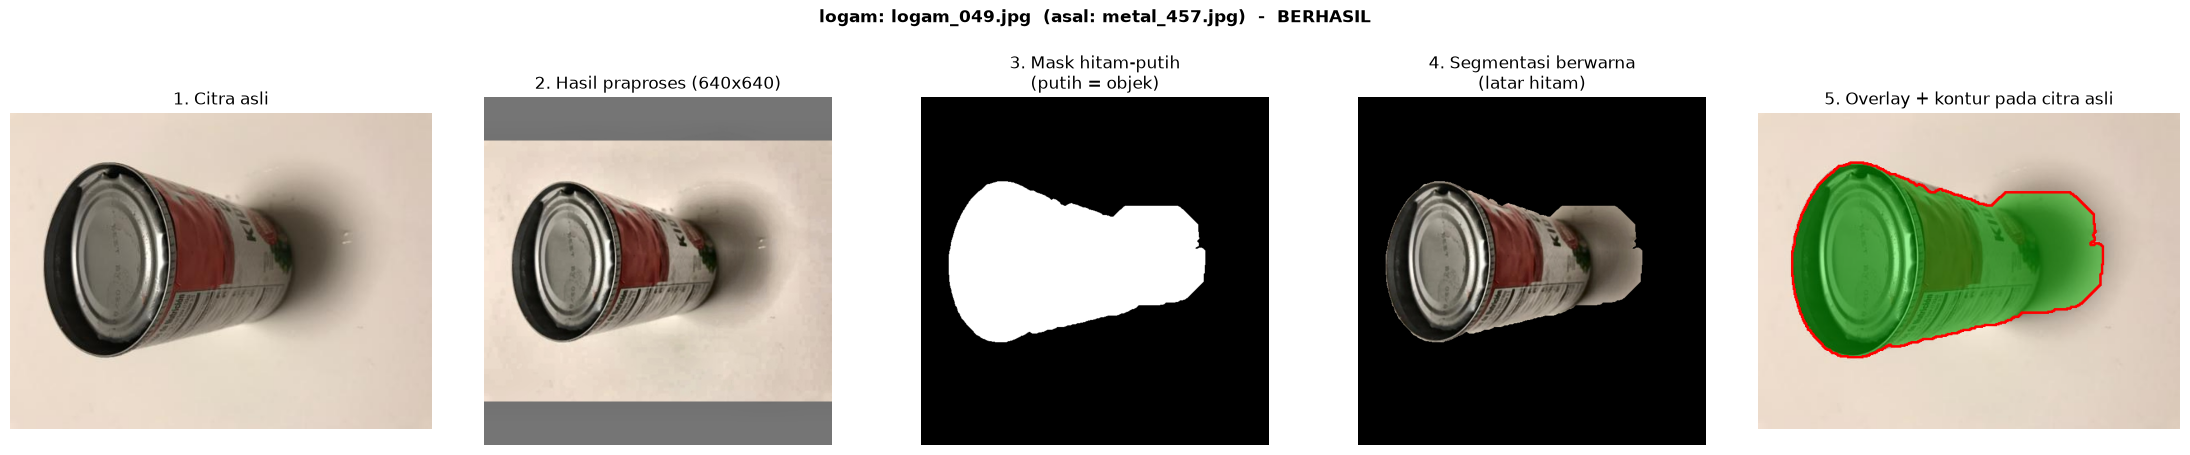

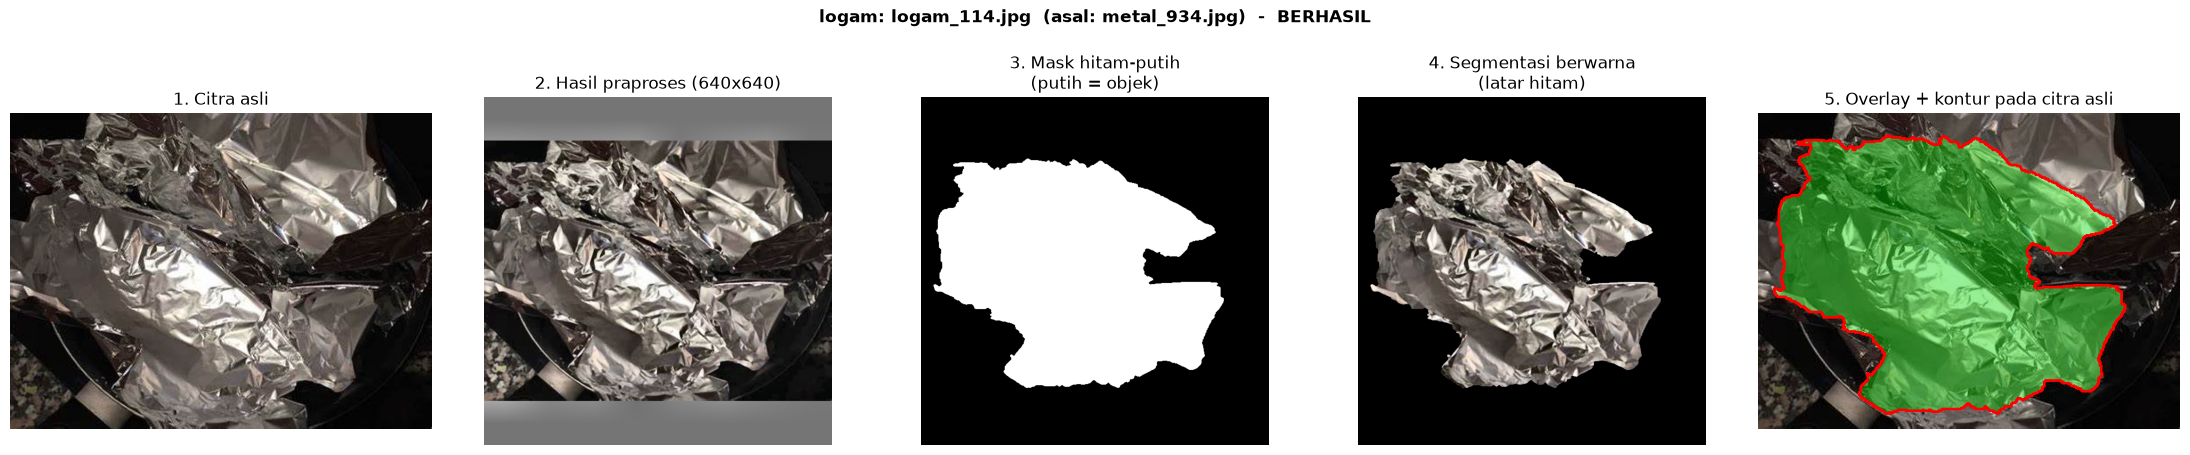

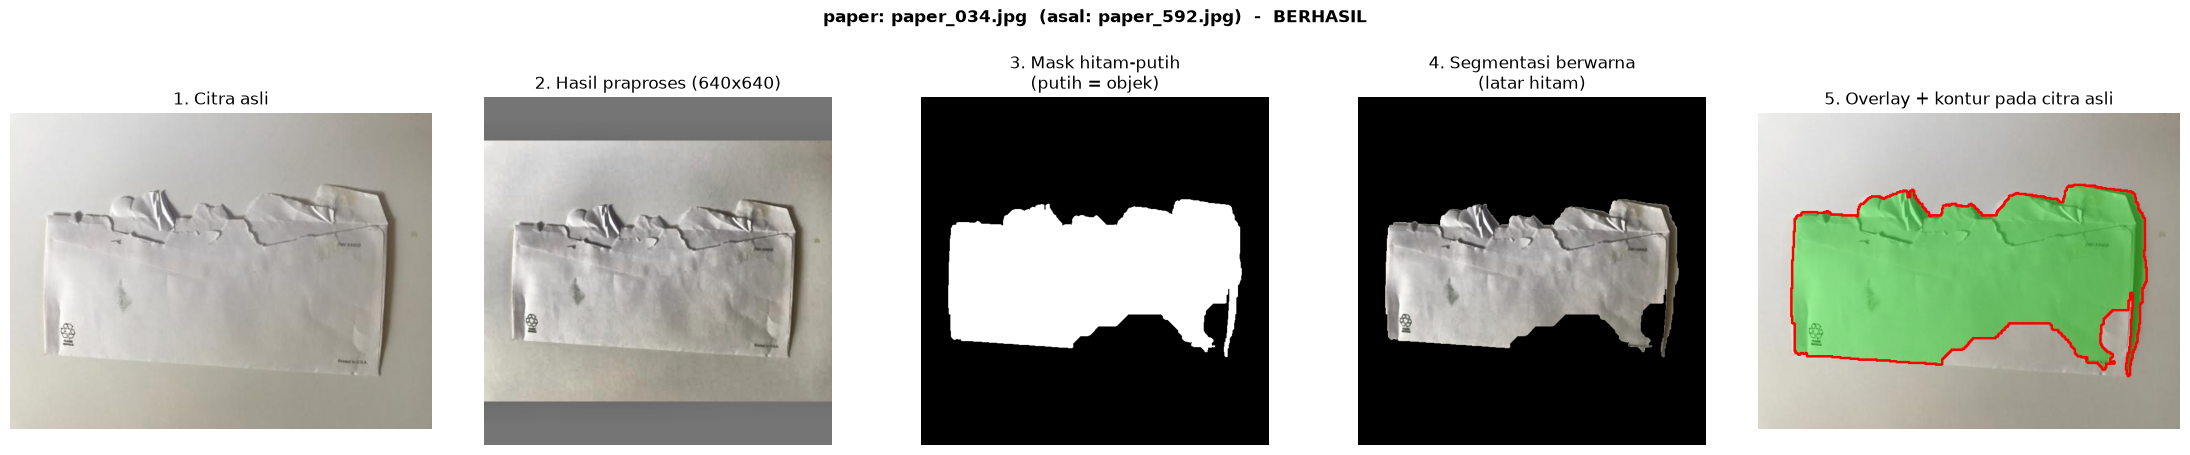

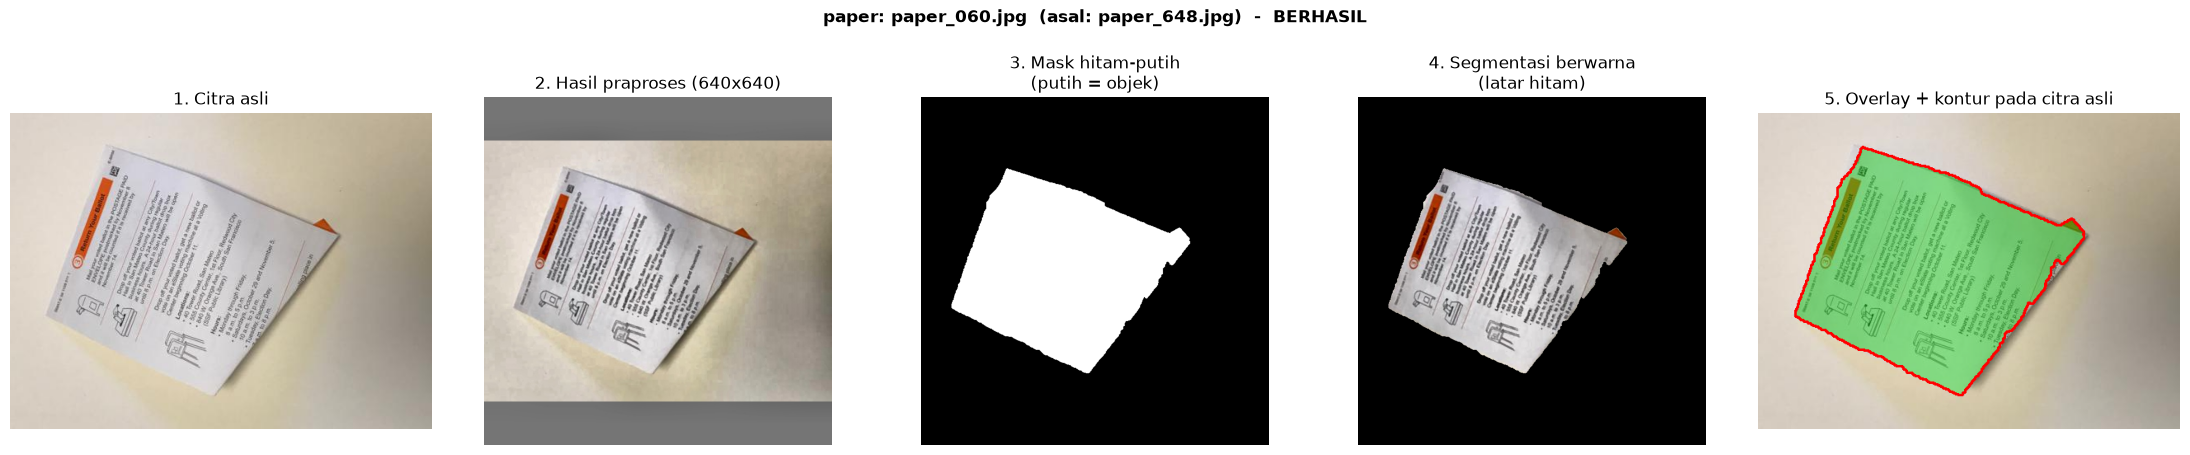

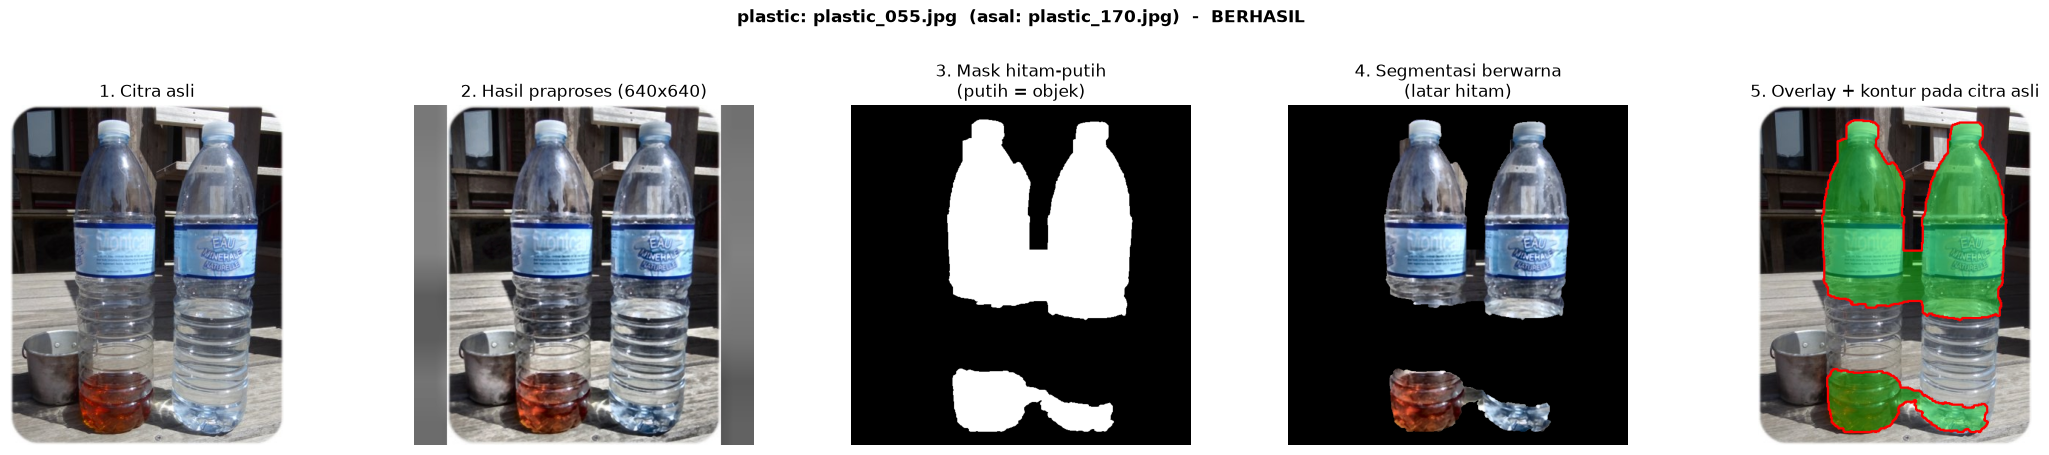

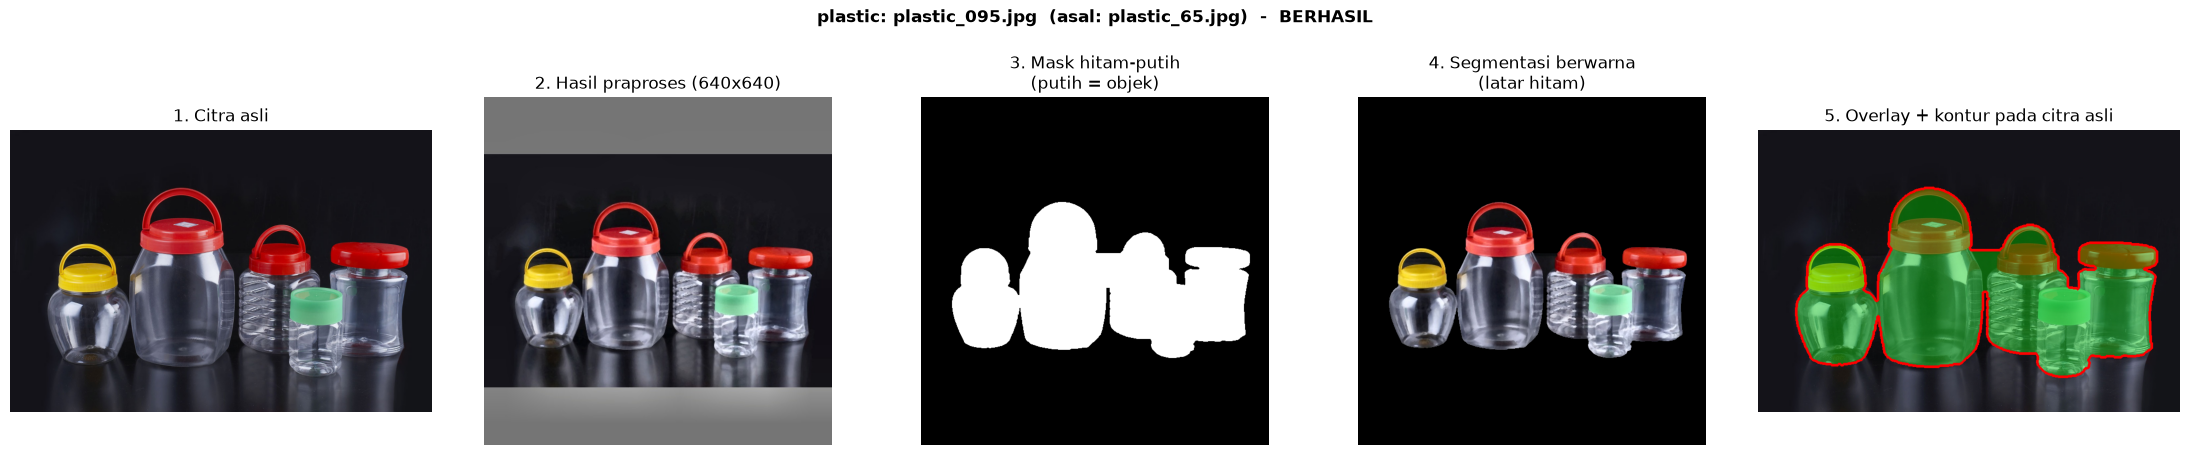

In [4]:
status = ringkasan.set_index("nama")["status"]
contoh = set(pd.concat([g.sample(min(JUMLAH_CONTOH, len(g)), random_state=1)
                        for _, g in tabel.groupby("kelas")])["nama_baru"])

for r in tabel.itertuples():
    if r.nama_baru not in contoh and not SIMPAN_SEMUA:
        continue
    nama_png = r.nama_baru.replace(".jpg", ".png")
    asli = baca(DATASET_RAW / r.kelas / r.nama_asli)
    praproses_img = baca(PRAPROSES / r.kelas / r.nama_baru)
    mask = baca(MASK / r.kelas / nama_png, gray=True)
    berwarna = baca(SEGMENTASI / r.kelas / nama_png)
    fig = gambar_segmentasi(r, asli, praproses_img, mask, berwarna, status[r.nama_baru])
    if SIMPAN_SEMUA:
        (HASIL / "perbandingan").mkdir(parents=True, exist_ok=True)
        fig.savefig(HASIL / "perbandingan" / nama_png, dpi=70)
    if r.nama_baru in contoh:
        plt.show()
    plt.close(fig)

## 5. Foto yang gagal disegmentasi



In [5]:
gagal = ringkasan[ringkasan["status"] == "gagal"]
print("Jumlah gagal per kelas:")
display(gagal["kelas"].value_counts().reindex(KELAS, fill_value=0).to_frame("gagal"))

if gagal.empty:
    print("Tidak ada foto yang ditandai gagal. Tetap periksa gambar di langkah 4 dengan mata, terutama logam, plastik transparan, dan paper.")
else:
    display(gagal[["nama", "kelas", "luas_objek_persen", "alasan"]])
    for r in tabel[tabel["nama_baru"].isin(gagal["nama"].head(4))].itertuples():
        nama_png = r.nama_baru.replace(".jpg", ".png")
        gambar_segmentasi(r, baca(DATASET_RAW / r.kelas / r.nama_asli), baca(PRAPROSES / r.kelas / r.nama_baru),
                          baca(MASK / r.kelas / nama_png, gray=True), baca(SEGMENTASI / r.kelas / nama_png), "gagal")
        plt.show()

Jumlah gagal per kelas:


,gagal
kelas,
logam,0
paper,0
plastic,0


Tidak ada foto yang ditandai gagal. Tetap periksa gambar di langkah 4 dengan mata, terutama logam, plastik transparan, dan paper.
